In [1]:
import numpy as np
from sklearn.linear_model import LogisticRegression

In [2]:
# 1. Input Features: 
#[Income_Lakhs, Docs_Complete]
X_apps = [ [2.5, 1], [8.0, 0], [3.0, 1],    [12.0, 0]]

# Target Labels: 
#1 = Approved, 0 = Rejected
y_decision = [1, 0, 1, 0]
# 2. Train the Classifier
classifier = LogisticRegression()
classifier.fit(X_apps, y_decision)

# 3. Predict for a new applicant: ₹3.5 Lakhs income, complete documents [3.5, 1]
new_applicant = [[3.5, 1]]
result = classifier.predict(new_applicant)

status = "Approved (1)" if result[0] == 1 else "Rejected (0)"
print(f"Application Result: {status}")

Application Result: Approved (1)


In [3]:
# 1. Input Features: [Income_Lakhs, Docs_Complete]
X_apps = np.array([
    [2.5, 1],
    [8.0, 0],
    [3.0, 1],
    [12.0, 0],
])
y_decision = np.array([1, 0, 1, 0])

# 2. Train the Classifier
classifier = LogisticRegression()
classifier.fit(X_apps, y_decision)

print("Coefficients [Income_Lakhs, Docs_Complete]:", classifier.coef_[0])
print("Intercept:", classifier.intercept_[0])

# 3. Predict class and probability for new applicant(s)
candidates = np.array([
    [3.5, 1],   # ₹3.5L, docs complete
    [10.0, 1],  # ₹10L, docs complete (tests income vs. docs trade-off)
    [3.5, 0],   # ₹3.5L, docs incomplete
])

preds = classifier.predict(candidates)
probs = classifier.predict_proba(candidates)

for app, pred, (p_rej, p_app) in zip(candidates, preds, probs):
    label = "Approved (1)" if pred == 1 else "Rejected (0)"
    print(f"{app.tolist()} -> {label} | P(Reject)={p_rej:.3f}, P(Approve)={p_app:.3f}")

Coefficients [Income_Lakhs, Docs_Complete]: [-0.79900189  0.14828583]
Intercept: 4.59037386425503
[3.5, 1.0] -> Approved (1) | P(Reject)=0.125, P(Approve)=0.875
[10.0, 1.0] -> Rejected (0) | P(Reject)=0.963, P(Approve)=0.037
[3.5, 0.0] -> Approved (1) | P(Reject)=0.143, P(Approve)=0.857


In [5]:
import matplotlib.pyplot as plt

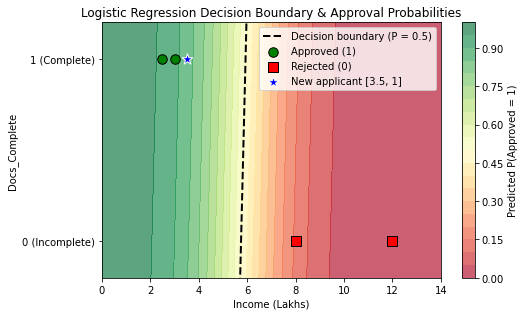

In [6]:
X_apps = np.array([
    [2.5, 1],
    [8.0, 0],
    [3.0, 1],
    [12.0, 0],
])
y_decision = np.array([1, 0, 1, 0])

clf = LogisticRegression().fit(X_apps, y_decision)

# Meshgrid over [Income_Lakhs, Docs_Complete]
x_min, x_max = 0.0, 14.0
y_min, y_max = -0.2, 1.2
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200),
)
probs = clf.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)

plt.figure(figsize=(7.5, 4.5))
contour = plt.contourf(xx, yy, probs, levels=20, cmap="RdYlGn", alpha=0.65)
plt.colorbar(contour, label="Predicted P(Approved = 1)")

# 50% decision boundary line: w1*x1 + w2*x2 + b = 0
w1, w2 = clf.coef_[0]
b = clf.intercept_[0]
if abs(w2) > 1e-6:
    x_vals = np.linspace(x_min, x_max, 200)
    y_boundary = -(w1 * x_vals + b) / w2
    plt.plot(x_vals, y_boundary, "k--", linewidth=2, label="Decision boundary (P = 0.5)")

# Plot observed training samples
approved = y_decision == 1
rejected = y_decision == 0
plt.scatter(
    X_apps[approved, 0], X_apps[approved, 1],
    c="green", edgecolors="black", s=90, label="Approved (1)"
)
plt.scatter(
    X_apps[rejected, 0], X_apps[rejected, 1],
    c="red", edgecolors="black", s=90, marker="s", label="Rejected (0)"
)

# Highlight new applicant [3.5, 1]
plt.scatter([3.5], [1.0], c="blue", edgecolors="white", s=130, marker="*", zorder=6, label="New applicant [3.5, 1]")

plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.yticks([0, 1], ["0 (Incomplete)", "1 (Complete)"])
plt.xlabel("Income (Lakhs)")
plt.ylabel("Docs_Complete")
plt.title("Logistic Regression Decision Boundary & Approval Probabilities")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()